<a href="https://colab.research.google.com/github/adtrmn/Road-to-be-a-Data-Analyst/blob/main/Day%201%20-%20Scrapping%20Data%20using%20Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests #untuk minta data dari internet
import pandas as pd #untuk membaca dan merapikan data
import sqlite3 # untuk menyimpan data ke database
import matplotlib.pyplot as plt #untuk membuat grafik
from datetime import datetime #untuk mengambil tanggal dan waktu saat ini

In [ ]:
url = "https://api.coingecko.com/api/v3/coins/bitcoin/market_chart"
params = {
    "vs_currency": "usd",
    "days": "30"
}
response = requests.get(url, params=params, timeout=30) #perintah untuk membaca data dari coingecko melalui api

In [ ]:
# Periksa apakah permintaan berhasil
response.raise_for_status()
hasil = response.json()
print("Data berhasil diambil dari CoinGecko!")
print("Bagian data yang tersedia:", hasil.keys())

Data berhasil diambil dari CoinGecko!
Bagian data yang tersedia: dict_keys(['prices', 'market_caps', 'total_volumes'])


In [ ]:
# Ambil daftar harga dari respon API
price = hasil["prices"]

In [ ]:
# Buat table dengan dua kolom
data = pd.DataFrame(price, columns=["timestamp", "price"])

In [ ]:
data

,timestamp,price
0,1792936800000,80299.909629
1,1792940400000,80560.488592
2,1792944000000,80556.804358
3,1792947600000,80718.947499
4,1792951200000,80714.158940
...,...,...
716,1795514400000,59915.744937
717,1795518000000,59702.161011
718,1795521600000,60374.437603
719,1795525200000,60390.425387


In [ ]:
# Data Cleaning untuk mengubah timestamp ke date
data["date"] = pd.to_datetime(data["timestamp"], unit="ms")

In [ ]:
data

,timestamp,price,date
0,1792936800000,80299.909629,2026-10-25 14:00:00
1,1792940400000,80560.488592,2026-10-25 15:00:00
2,1792944000000,80556.804358,2026-10-25 16:00:00
3,1792947600000,80718.947499,2026-10-25 17:00:00
4,1792951200000,80714.158940,2026-10-25 18:00:00
...,...,...,...
716,1795514400000,59915.744937,2026-11-24 10:00:00
717,1795518000000,59702.161011,2026-11-24 11:00:00
718,1795521600000,60374.437603,2026-11-24 12:00:00
719,1795525200000,60390.425387,2026-11-24 13:00:00


In [ ]:
koneksi = sqlite3.connect("crypto.db")
data.to_sql(
    name="bitcoin_prices",
    con=koneksi,
    if_exists="replace",
    index=False
)
koneksi.close()
print("Data berhasil disimpan ke crypto.db")

Data berhasil disimpan ke crypto.db


In [ ]:
koneksi = sqlite3.connect("crypto.db")
data_sql = pd.read_sql_query(
    "SELECT * FROM bitcoin_prices ORDER BY date",
    koneksi
)
koneksi.close()
print("Jumlah baris:", len(data_sql))
data_sql.head()

Jumlah baris: 721


,timestamp,price,date
0,1792936800000,80299.909629,2026-10-25 14:00:00
1,1792940400000,80560.488592,2026-10-25 15:00:00
2,1792944000000,80556.804358,2026-10-25 16:00:00
3,1792947600000,80718.947499,2026-10-25 17:00:00
4,1792951200000,80714.158940,2026-10-25 18:00:00


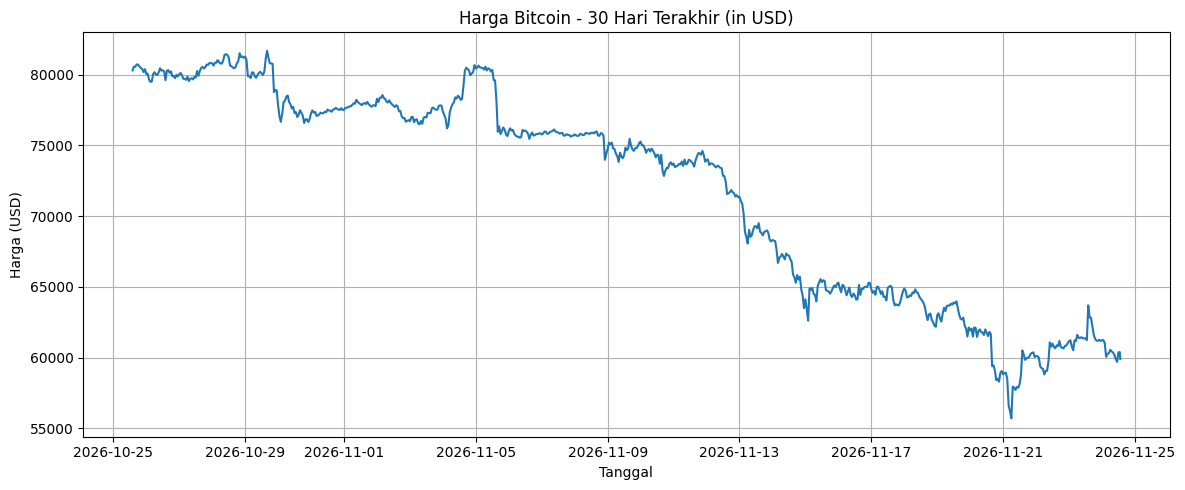

In [ ]:
data_sql["date"] = pd.to_datetime(data_sql["date"])
plt.figure(figsize=(12, 5))
plt.plot(data_sql["date"], data_sql["price"])
plt.title("Harga Bitcoin - 30 Hari Terakhir (in USD)")
plt.xlabel("Tanggal")
plt.ylabel("Harga (USD)")
plt.grid(True)
plt.tight_layout()
plt.show()